<a href="https://colab.research.google.com/github/alfredobrocalserrano/tfm-salarios-ees/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Análisis exploratorio (EDA)

**Objetivo:** entender cómo se distribuye el salario y qué características del trabajador y de la empresa se asocian con él, antes de construir los modelos. Las conclusiones del final guían las decisiones de preparación de datos (notebook 03) y de modelización (notebook 04).

El análisis se centra en **2022** (la edición más reciente) y compara con 2018 en la sección 7. Salvo que se indique lo contrario, todas las cifras están **ponderadas con el factor de elevación** (`FACTOTAL`), es decir, representan al conjunto de asalariados y no solo a la muestra.

Fuente: INE, www.ine.es.

### Preparación del entorno

Funciona tanto en local (abriendo el notebook dentro del repositorio clonado) como en **Google Colab**: si se abre en Colab sin el repositorio, lo descarga de GitHub automáticamente y, si hacen falta, pide subir los microdatos del INE.

In [1]:
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/alfredobrocalserrano/tfm-salarios-ees"
EN_COLAB = "google.colab" in sys.modules


def buscar_raiz():
    """Devuelve la carpeta del proyecto (la que contiene src/) o None si no está."""
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "src").is_dir():
            return carpeta
    return None


RAIZ = buscar_raiz()
if RAIZ is None:
    if EN_COLAB:
        RAIZ = Path("/content/tfm-salarios-ees")
        if not RAIZ.exists():
            print("Descargando el repositorio del proyecto...")
            subprocess.run(["git", "clone", "-q", REPO_URL, str(RAIZ)], check=True)
    else:
        raise FileNotFoundError(
            "No se encuentra la carpeta src/ del proyecto. Clona el repositorio "
            f"({REPO_URL}) y abre el notebook desde dentro (ver README)."
        )

sys.path.insert(0, str(RAIZ))
print("Carpeta del proyecto:", RAIZ)

Descargando el repositorio del proyecto...
Carpeta del proyecto: /content/tfm-salarios-ees


In [3]:
# Solo en Colab: si no está el dataset procesado ni los microdatos del INE, se piden para subirlos
if EN_COLAB and not (RAIZ / "data" / "processed" / "ees_2018_2022.parquet").exists():
    from google.colab import files

    carpeta_raw = RAIZ / "data" / "raw"
    carpeta_raw.mkdir(parents=True, exist_ok=True)
    faltan = [a for a in (2018, 2022) if not (carpeta_raw / f"md_EES_{a}.parquet").exists()]
    if faltan:
        print("Sube los ficheros:", ", ".join(f"md_EES_{a}.parquet" for a in faltan))
        for nombre, contenido in files.upload().items():
            for anio in faltan:
                if str(anio) in nombre and nombre.endswith(".parquet"):
                    (carpeta_raw / f"md_EES_{anio}.parquet").write_bytes(contenido)
                    print("Guardado:", f"md_EES_{anio}.parquet")

Sube los ficheros: md_EES_2018.parquet


Saving md_EES_2018.parquet to md_EES_2018.parquet
Guardado: md_EES_2018.parquet


In [4]:
try:
    import duckdb
except ImportError:  # por si el entorno (p. ej. Colab) no lo trae instalado
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb"], check=True)
    import duckdb

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from src.datos import cargar_dataset_procesado
from src.estadistica import (
    cuantil_ponderado, mediana_ponderada, resumen_ponderado, v_cramer, eta_cuadrado,
)

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", font_scale=0.95)
EUROS = mticker.FuncFormatter(lambda x, _: f"{x:,.0f} €".replace(",", "."))
MILES = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
AZUL, ROJO, GRIS = "#3B6EA5", "#C0392B", "#7F8C8D"

## 1. Carga de datos y variables derivadas

In [5]:
ees = cargar_dataset_procesado()  # lo genera el notebook 01 (o lo reconstruye si no existe)

ees["antiguedad"] = ees["ANOANTI"] + ees["MESANTI"] / 12   # años en la empresa
ees["salario_hora"] = ees["salario_anual"] / ees["JAP"]     # JAP = jornada anual pactada (horas)
ees["log_salario"] = np.log(ees["salario_anual"])

e22 = ees[ees["anio"] == 2022].copy()
print(f"Total: {len(ees):,} registros | 2022: {len(e22):,} | 2018: {(ees.anio == 2018).sum():,}")

Total: 457,216 registros | 2022: 240,490 | 2018: 216,726


## 2. Por qué hay que ponderar

La muestra no es proporcional a la población: el INE encuesta a **todas** las empresas grandes (más de 500 trabajadores) y solo a una parte de las pequeñas. Si se calculan medias sin ponderar, las empresas grandes, que pagan más, pesan demasiado.

In [6]:
w, s = e22["FACTOTAL"], e22["salario_anual"]

pd.DataFrame(
    {
        "Sin ponderar": [s.mean(), s.median()],
        "Ponderado (FACTOTAL)": [np.average(s, weights=w), mediana_ponderada(s, w)],
        "Publicado por el INE": [26948.87, 22383.11],
    },
    index=["Media", "Mediana"],
).round(0)

,Sin ponderar,Ponderado (FACTOTAL),Publicado por el INE
Media,31025.0,26946.0,26949.0
Mediana,24769.0,22381.0,22383.0


In [7]:
# Peso de cada tamaño de empresa en la muestra frente a la población que representa
pd.DataFrame({
    "% de registros": e22["tamano_empresa"].value_counts(normalize=True) * 100,
    "% de la población": e22.groupby("tamano_empresa", observed=True)["FACTOTAL"].sum() / w.sum() * 100,
}).round(1)

,% de registros,% de la población
tamano_empresa,,
Sin desagregar (todos los tamaños),0.6,0.2
De 1 a 49 trabajadores,27.2,45.6
De 50 a 199 trabajadores,25.0,19.1
200 o más trabajadores,45.6,34.6
50 o más (sin desagregar),1.6,0.5


Sin ponderar, la media sale un 15 % más alta que la real. Con `FACTOTAL`, la media y la **mediana coinciden con las publicadas por el INE** (26.948,87 € y 22.383,11 €), lo que confirma de nuevo que la variable objetivo y la ponderación son correctas. Las empresas de 200 o más trabajadores son el 45 % de los registros, pero solo un tercio de los asalariados.

## 3. Distribución del salario

In [8]:
percentiles = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
pd.DataFrame(
    {"Salario bruto anual": cuantil_ponderado(s, w, percentiles)},
    index=[f"P{p * 100:g}" for p in percentiles],
).round(0)

,Salario bruto anual
P1,3250.0
P5,7399.0
P10,10657.0
P25,15912.0
P50,22381.0
P75,33558.0
P90,48212.0
P95,60633.0
P99,89195.0
P99.9,127619.0


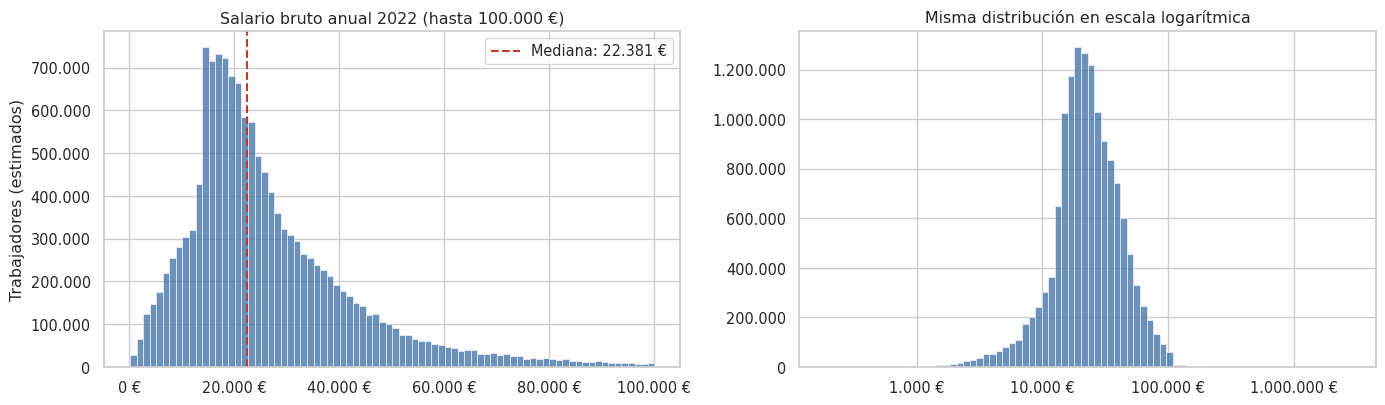

In [9]:
mediana_22 = mediana_ponderada(s, w)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))

sns.histplot(data=e22[s < 100_000], x="salario_anual", weights="FACTOTAL", bins=80, color=AZUL, ax=ax[0])
ax[0].axvline(mediana_22, color=ROJO, ls="--", label=f"Mediana: {mediana_22:,.0f} €".replace(",", "."))
ax[0].xaxis.set_major_formatter(EUROS)
ax[0].yaxis.set_major_formatter(MILES)
ax[0].set(title="Salario bruto anual 2022 (hasta 100.000 €)", xlabel="", ylabel="Trabajadores (estimados)")
ax[0].legend()

sns.histplot(data=e22, x="salario_anual", weights="FACTOTAL", bins=80, log_scale=True, color=AZUL, ax=ax[1])
ax[1].xaxis.set_major_formatter(EUROS)
ax[1].yaxis.set_major_formatter(MILES)
ax[1].set(title="Misma distribución en escala logarítmica", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

La distribución tiene una **cola larga a la derecha** (pocos sueldos muy altos), típica de los salarios. En escala logarítmica se vuelve bastante simétrica, por eso en la modelización se trabajará con el **logaritmo del salario**. La cola izquierda en la escala logarítmica corresponde a contratos a tiempo parcial, como se ve a continuación.

### 3.1 Valores extremos

In [10]:
pd.DataFrame(
    {"Registros": [
        (s < 5_000).sum(),
        ((s < 5_000) & (e22["jornada"] == "Tiempo parcial")).sum(),
        (s > 200_000).sum(),
        (s > 500_000).sum(),
    ]},
    index=["Salario < 5.000 €", "   de ellos, a tiempo parcial", "Salario > 200.000 €", "Salario > 500.000 €"],
)

,Registros
Salario < 5.000 €,4645
"de ellos, a tiempo parcial",4645
Salario > 200.000 €,645
Salario > 500.000 €,83


In [11]:
# ¿Quiénes cobran más de 200.000 €?
e22.loc[s > 200_000, "ocupacion"].value_counts().head(5)

,count
ocupacion,
Directores y gerentes,381
Otros técnicos y profesionales científicos,128
Técnicos y profesionales de apoyo,119
Profesionales de la salud y la enseñanza,8
Empleados de oficina sin atención al público,5


In [12]:
# Salario anual y salario por hora según la jornada
resumen_jornada = resumen_ponderado(e22, "jornada")[["jornada", "poblacion_%", "p25", "mediana", "p75"]]
resumen_jornada["mediana_por_hora"] = [
    mediana_ponderada(g["salario_hora"], g["FACTOTAL"]) for _, g in e22.groupby("jornada", observed=True)
]
resumen_jornada.round(1)

,jornada,poblacion_%,p25,mediana,p75,mediana_por_hora
0,Tiempo completo,77.5,19237.3,25685.1,37421.3,14.9
1,Tiempo parcial,22.5,7857.3,11618.1,16009.0,10.8


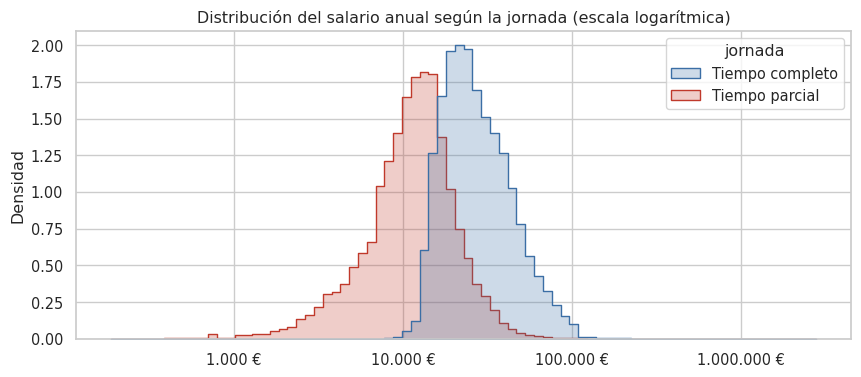

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=e22, x="salario_anual", hue="jornada", weights="FACTOTAL", bins=80, log_scale=True,
             element="step", stat="density", common_norm=False, palette=[AZUL, ROJO], ax=ax)
ax.xaxis.set_major_formatter(EUROS)
ax.set(title="Distribución del salario anual según la jornada (escala logarítmica)", xlabel="", ylabel="Densidad")
plt.show()

- **Todos** los salarios por debajo de 5.000 € son de contratos **a tiempo parcial**: no son errores, sino personas que trabajan pocas horas. No deben eliminarse.
- En el extremo alto hay 645 registros por encima de 200.000 €, sobre todo directivos. Son reales, pero muy escasos e influyentes: en el notebook 03 se decidirá si se recortan (por ejemplo, al percentil 99,9) para que no distorsionen el modelo.
- La jornada es decisiva: el tiempo parcial (22,5 % de los asalariados) cobra **menos de la mitad al año**, pero la diferencia **por hora** es mucho menor. El modelo necesitará saber la jornada y, si es posible, las horas trabajadas.

## 4. Salario según las características del trabajador y de la empresa

In [14]:
def grafico_medianas(variable, datos=e22, ordenar=True, titulo=None):
    """Barras con la mediana ponderada por grupo y el rango intercuartílico (P25–P75)."""
    r = resumen_ponderado(datos, variable)
    if ordenar:
        r = r.sort_values("mediana")
    etiquetas = r[variable].astype(str)
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(r) + 1.2))
    ax.barh(etiquetas, r["mediana"], color=AZUL)
    ax.errorbar(r["mediana"], etiquetas, xerr=[r["mediana"] - r["p25"], r["p75"] - r["mediana"]],
                fmt="none", ecolor=GRIS, capsize=2, lw=1)
    ax.axvline(mediana_ponderada(datos["salario_anual"], datos["FACTOTAL"]), color=ROJO, ls="--", lw=1,
               label="Mediana general")
    ax.xaxis.set_major_formatter(EUROS)
    ax.set(xlabel="Salario bruto anual mediano (las líneas grises marcan P25–P75)", ylabel="",
           title=titulo or f"Salario mediano por {variable} (2022)")
    ax.legend(loc="lower right")
    plt.show()
    return r

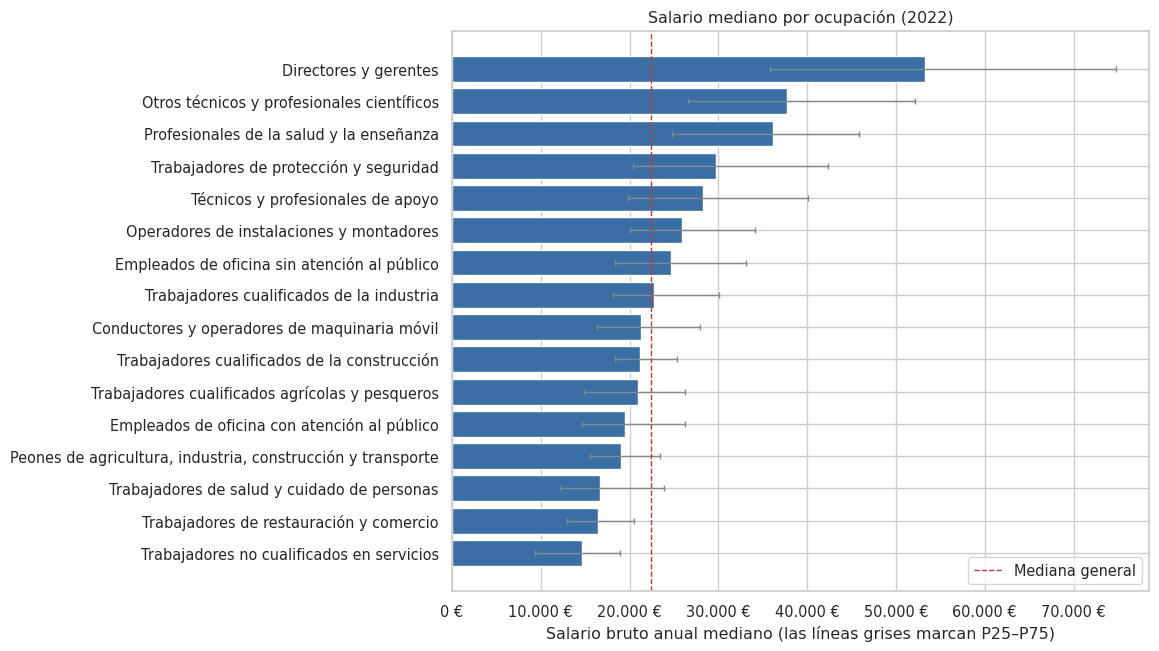

,ocupacion,poblacion_%,mediana
14,Trabajadores no cualificados en servicios,7.7,14605.6
6,Trabajadores de restauración y comercio,12.5,16470.9
7,Trabajadores de salud y cuidado de personas,6.6,16684.7
15,"Peones de agricultura, industria, construcción...",5.6,19031.8
5,Empleados de oficina con atención al público,6.8,19517.6
9,Trabajadores cualificados agrícolas y pesqueros,0.5,20923.5
10,Trabajadores cualificados de la construcción,3.4,21147.5
13,Conductores y operadores de maquinaria móvil,4.8,21274.3
11,Trabajadores cualificados de la industria,6.9,22799.7
4,Empleados de oficina sin atención al público,5.8,24672.8


In [15]:
grafico_medianas("ocupacion", titulo="Salario mediano por ocupación (2022)")[["ocupacion", "poblacion_%", "mediana"]].round(1)

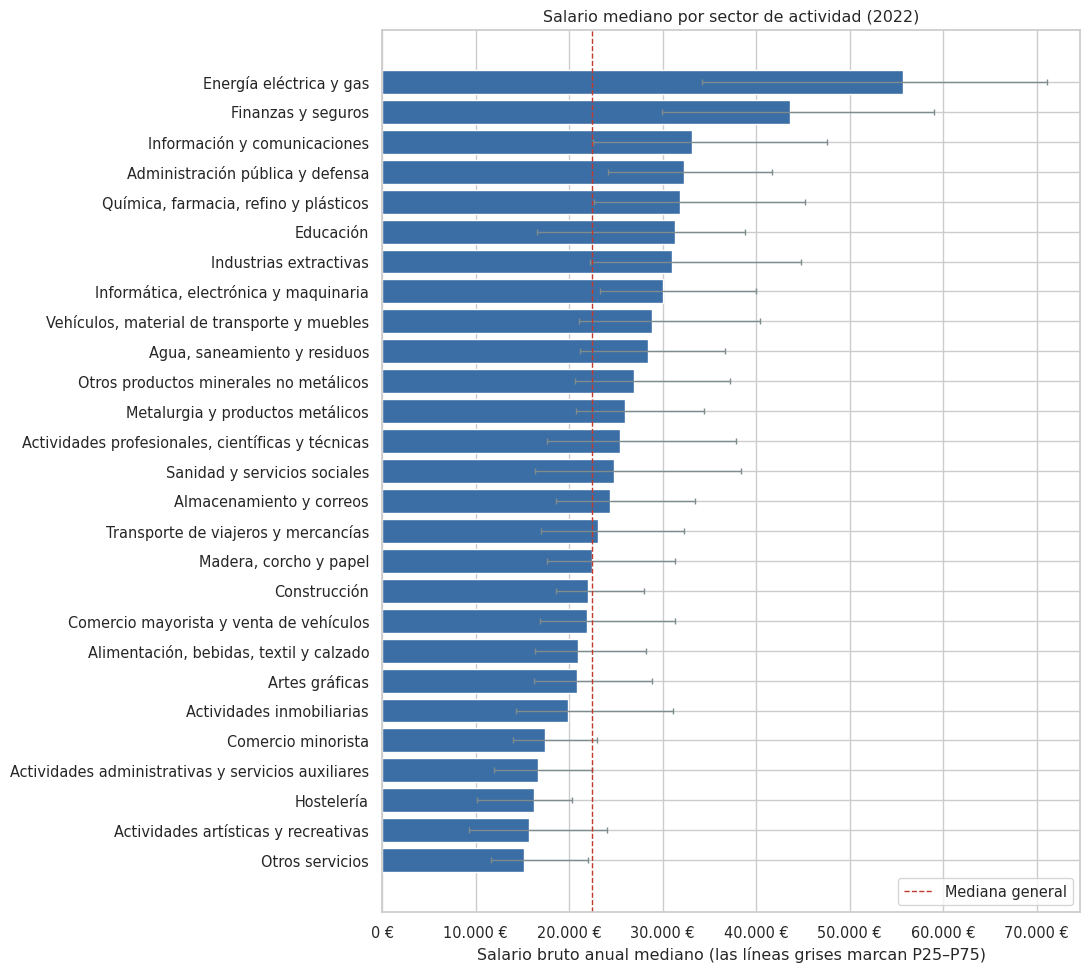

In [16]:
grafico_medianas("sector", titulo="Salario mediano por sector de actividad (2022)");

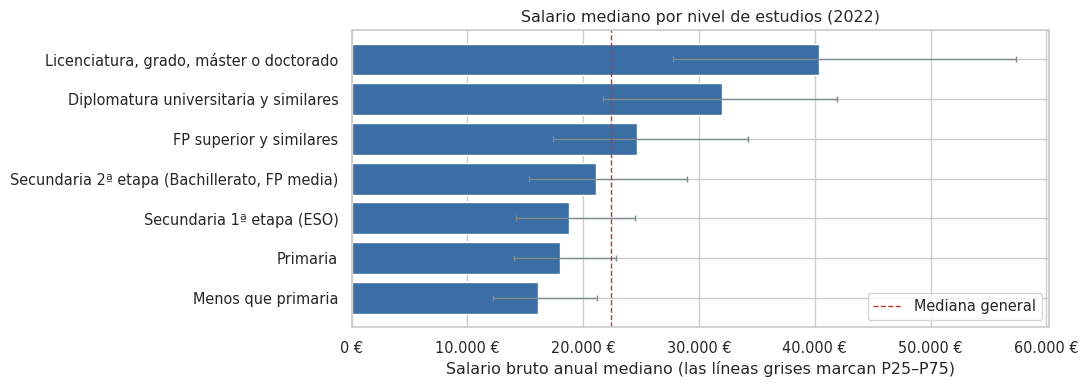

,estudios,poblacion_%,mediana
0,Menos que primaria,0.6,16137.6
1,Primaria,15.6,17998.0
2,Secundaria 1ª etapa (ESO),24.7,18746.6
3,"Secundaria 2ª etapa (Bachillerato, FP media)",20.6,21076.2
4,FP superior y similares,9.1,24658.7
5,Diplomatura universitaria y similares,14.8,31993.0
6,"Licenciatura, grado, máster o doctorado",14.6,40383.4


In [17]:
grafico_medianas("estudios", ordenar=False, titulo="Salario mediano por nivel de estudios (2022)")[["estudios", "poblacion_%", "mediana"]].round(1)

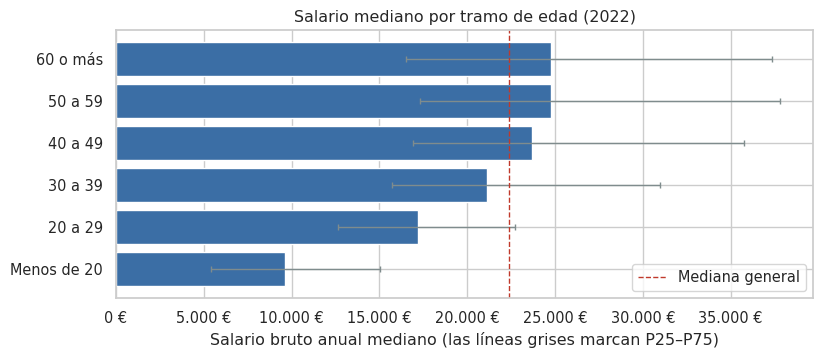

In [18]:
grafico_medianas("edad", ordenar=False, titulo="Salario mediano por tramo de edad (2022)");

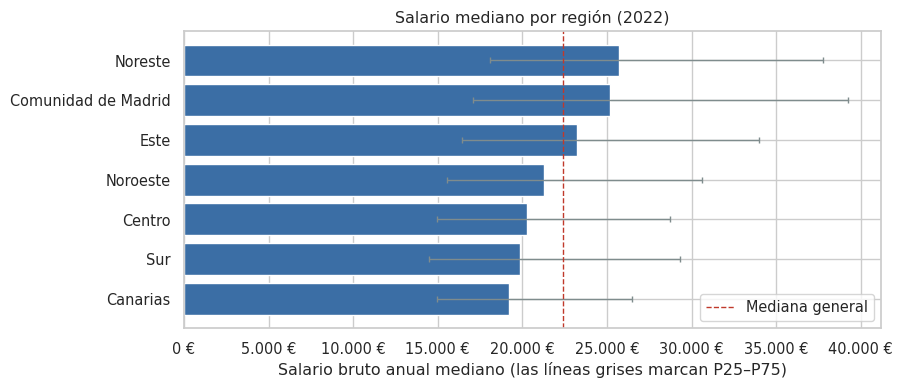

In [19]:
grafico_medianas("region", titulo="Salario mediano por región (2022)");

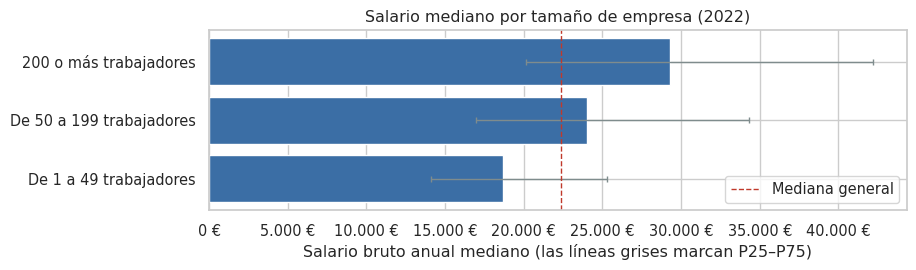

In [20]:
# Se excluyen los códigos sin desagregar (2,4 % de los registros), que no corresponden a un tamaño concreto
tamanos_reales = ["De 1 a 49 trabajadores", "De 50 a 199 trabajadores", "200 o más trabajadores"]
grafico_medianas("tamano_empresa", datos=e22[e22["tamano_empresa"].isin(tamanos_reales)], ordenar=False,
                 titulo="Salario mediano por tamaño de empresa (2022)");

In [21]:
# Variables con pocas categorías, en una sola tabla
tablas = []
for variable in ["control", "contrato", "jornada", "responsabilidad", "nacionalidad", "mercado", "convenio"]:
    r = resumen_ponderado(e22, variable).rename(columns={variable: "categoria"})
    r.insert(0, "variable", variable)
    tablas.append(r[["variable", "categoria", "poblacion_%", "mediana"]])
pd.concat(tablas, ignore_index=True).round(1)

,variable,categoria,poblacion_%,mediana
0,control,Público,21.0,32540.6
1,control,Privado,79.0,20473.8
2,contrato,Indefinido,88.3,22434.7
3,contrato,Temporal,11.7,21957.8
4,jornada,Tiempo completo,77.5,25685.1
5,jornada,Tiempo parcial,22.5,11618.1
6,responsabilidad,Con responsabilidad,12.0,37336.3
7,responsabilidad,Sin responsabilidad,88.0,21164.1
8,nacionalidad,España,90.9,23044.1
9,nacionalidad,Resto del mundo,9.1,18130.8


### 4.1 Antigüedad en la empresa

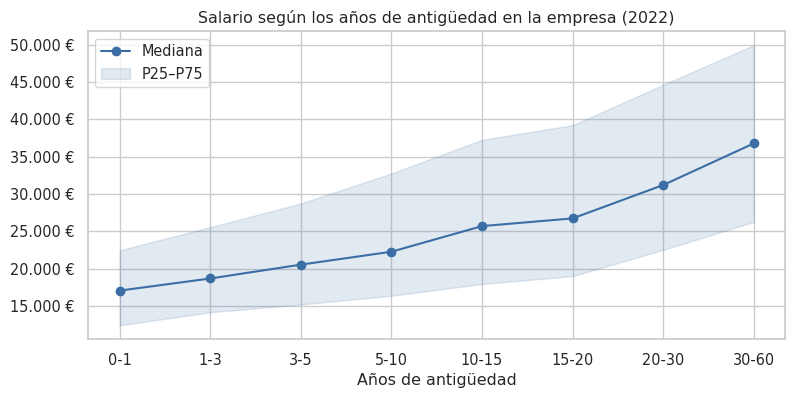

In [22]:
tramos = [0, 1, 3, 5, 10, 15, 20, 30, 60]
e22["tramo_antiguedad"] = pd.cut(e22["antiguedad"], tramos, right=False,
                                 labels=[f"{a}-{b}" for a, b in zip(tramos[:-1], tramos[1:])])
r = resumen_ponderado(e22, "tramo_antiguedad")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(r["tramo_antiguedad"].astype(str), r["mediana"], marker="o", color=AZUL, label="Mediana")
ax.fill_between(r["tramo_antiguedad"].astype(str), r["p25"], r["p75"], color=AZUL, alpha=0.15, label="P25–P75")
ax.yaxis.set_major_formatter(EUROS)
ax.set(title="Salario según los años de antigüedad en la empresa (2022)", xlabel="Años de antigüedad", ylabel="")
ax.legend()
plt.show()

## 5. ¿Qué variables explican más el salario?

Para comparar todas las variables en una misma escala se usa **η² (eta cuadrado)**: la proporción de la variabilidad del logaritmo del salario que explican los grupos de cada variable por separado (0 = nada, 1 = todo). Es una primera aproximación a la importancia de cada variable, antes de cualquier modelo.

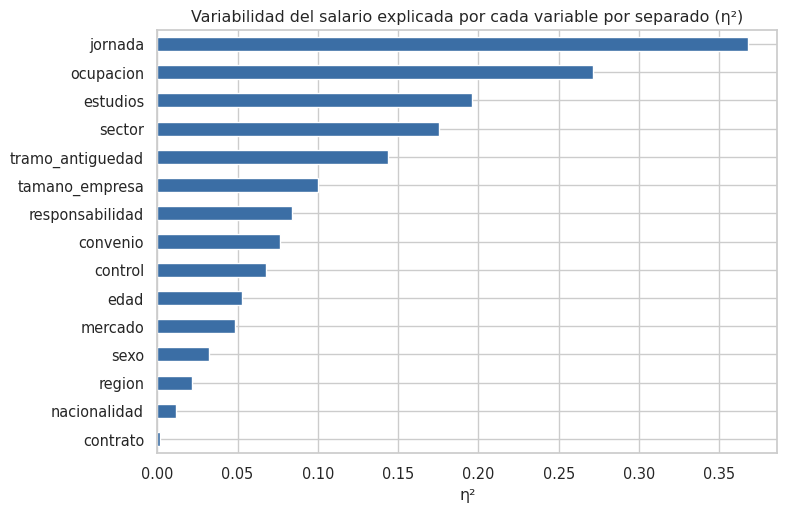

In [23]:
predictores = ["jornada", "ocupacion", "estudios", "sector", "tamano_empresa", "responsabilidad", "convenio",
               "control", "edad", "mercado", "sexo", "region", "nacionalidad", "contrato", "tramo_antiguedad"]
eta2 = pd.Series({v: eta_cuadrado(e22[v], e22["log_salario"], e22["FACTOTAL"]) for v in predictores}).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
eta2.plot.barh(color=AZUL, ax=ax)
ax.set(title="Variabilidad del salario explicada por cada variable por separado (η²)", xlabel="η²")
plt.show()

Las variables no son independientes entre sí: por ejemplo, la ocupación y los estudios van muy unidos. La **V de Cramér** mide la asociación entre pares de variables categóricas (0 = ninguna, 1 = total). Asociaciones altas avisan de información redundante y de que la importancia de una variable puede "robarse" a otra en los modelos.

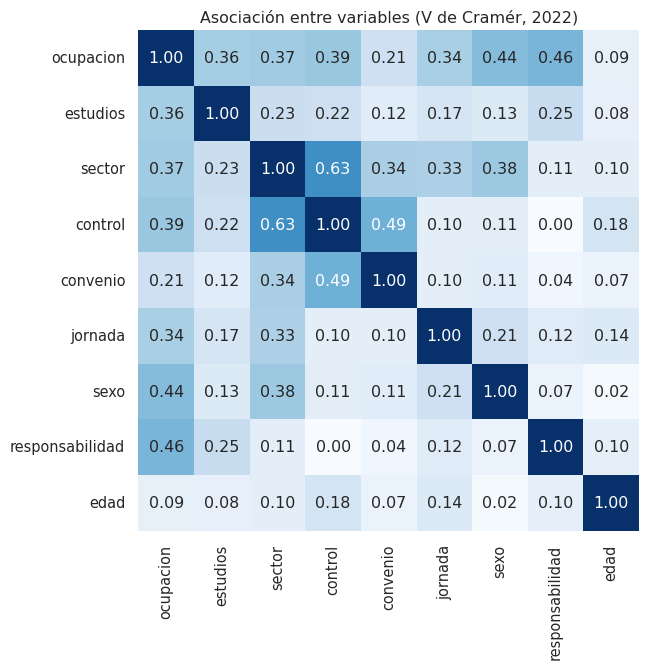

In [24]:
variables = ["ocupacion", "estudios", "sector", "control", "convenio", "jornada", "sexo", "responsabilidad", "edad"]
matriz = pd.DataFrame(index=variables, columns=variables, dtype=float)
for a in variables:
    for b in variables:
        matriz.loc[a, b] = 1.0 if a == b else v_cramer(e22[a], e22[b])

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, cbar=False, ax=ax)
ax.set_title("Asociación entre variables (V de Cramér, 2022)")
plt.show()

## 6. Primera mirada a la brecha salarial entre hombres y mujeres

Aquí solo se describe la **brecha bruta** (sin tener en cuenta ocupación, jornada, etc.). La brecha **ajustada**, que compara a hombres y mujeres con el mismo perfil, se estudiará con el modelo en el notebook 05.

In [25]:
def brecha(datos, valor):
    h = datos[datos["sexo"] == "Hombre"]
    m = datos[datos["sexo"] == "Mujer"]
    media_h, media_m = np.average(h[valor], weights=h["FACTOTAL"]), np.average(m[valor], weights=m["FACTOTAL"])
    med_h, med_m = mediana_ponderada(h[valor], h["FACTOTAL"]), mediana_ponderada(m[valor], m["FACTOTAL"])
    return {"brecha en la media (%)": 100 * (media_h - media_m) / media_h,
            "brecha en la mediana (%)": 100 * (med_h - med_m) / med_h}

pd.DataFrame({
    "Todos, salario anual": brecha(e22, "salario_anual"),
    "Solo tiempo completo, salario anual": brecha(e22[e22["jornada"] == "Tiempo completo"], "salario_anual"),
    "Todos, salario por hora": brecha(e22, "salario_hora"),
}).T.round(1)

,brecha en la media (%),brecha en la mediana (%)
"Todos, salario anual",17.1,17.3
"Solo tiempo completo, salario anual",5.8,3.7
"Todos, salario por hora",10.0,10.9


In [ ]:
# Porcentaje de trabajadores a tiempo parcial según el sexo
(e22[e22["jornada"] == "Tiempo parcial"].groupby("sexo", observed=True)["FACTOTAL"].sum()
 / e22.groupby("sexo", observed=True)["FACTOTAL"].sum() * 100).round(1).rename("% a tiempo parcial")

sexo
Hombre    13.5
Mujer     32.1
Name: % a tiempo parcial, dtype: float64

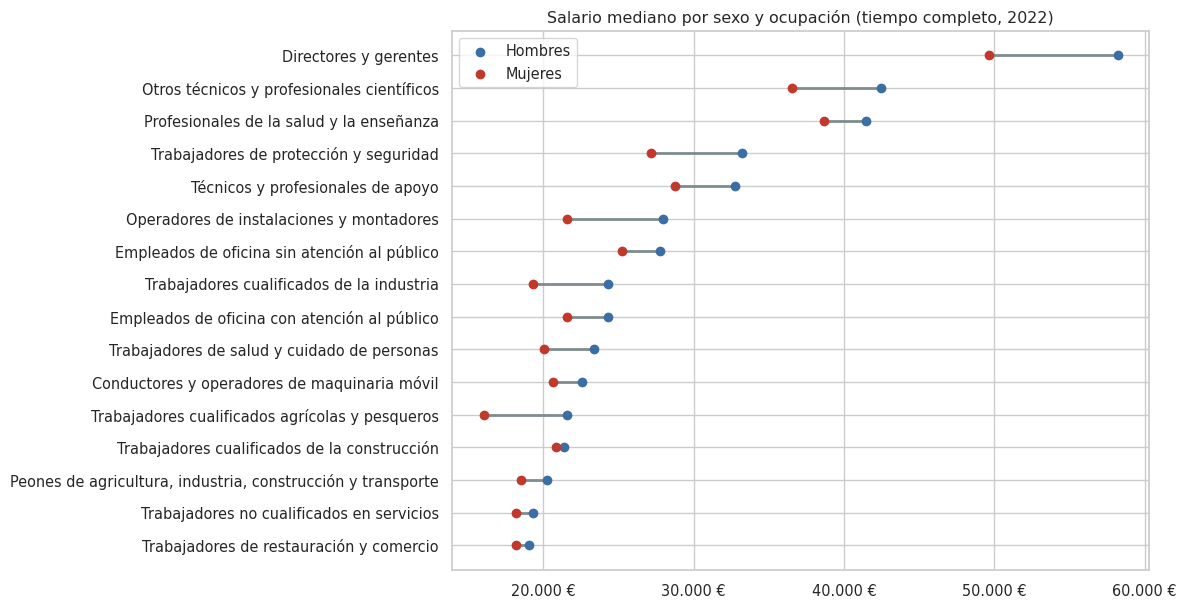

In [26]:
# Mediana por sexo dentro de cada ocupación (solo tiempo completo)
r = resumen_ponderado(e22[e22["jornada"] == "Tiempo completo"], ["ocupacion", "sexo"])
tabla = r.pivot(index="ocupacion", columns="sexo", values="mediana").dropna().sort_values("Hombre")

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(tabla.index, tabla["Mujer"], tabla["Hombre"], color=GRIS, lw=2)
ax.scatter(tabla["Hombre"], tabla.index, color=AZUL, label="Hombres", zorder=3)
ax.scatter(tabla["Mujer"], tabla.index, color=ROJO, label="Mujeres", zorder=3)
ax.xaxis.set_major_formatter(EUROS)
ax.set(title="Salario mediano por sexo y ocupación (tiempo completo, 2022)", xlabel="", ylabel="")
ax.legend()
plt.show()

La brecha bruta en la mediana del salario anual es grande, pero **se reduce mucho al comparar solo a personas a tiempo completo** o al mirar el salario por hora. La razón principal es que las mujeres trabajan a tiempo parcial más del doble que los hombres. Aun así, dentro de casi todas las ocupaciones los hombres siguen cobrando algo más. Separar qué parte de la brecha se explica por el perfil y qué parte no es justamente el análisis del notebook 05.

## 7. Qué cambió entre 2018 y 2022

Las cifras son **nominales** (sin descontar la inflación); en el notebook 03 se deflactarán con el IPC. En ese periodo hubo dos cambios importantes:
- El **salario mínimo interprofesional (SMI)** pasó de 735,90 €/mes en 2018 a 1.000 €/mes en 2022 (14 pagas: de 10.302,60 € a 14.000 € al año).
- La **reforma laboral** de 2021 redujo mucho los contratos temporales.

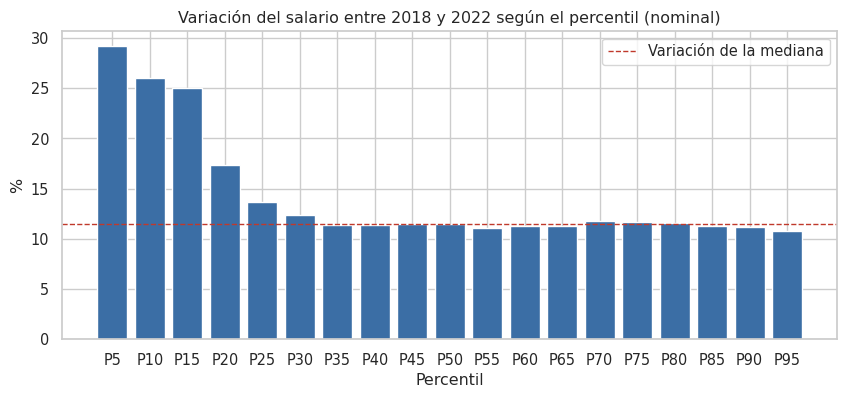

In [27]:
cuantiles = np.arange(0.05, 0.96, 0.05)
e18 = ees[ees["anio"] == 2018]
q18 = cuantil_ponderado(e18["salario_anual"], e18["FACTOTAL"], cuantiles)
q22 = cuantil_ponderado(e22["salario_anual"], e22["FACTOTAL"], cuantiles)
cambio = 100 * (q22 / q18 - 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([f"P{c * 100:.0f}" for c in cuantiles], cambio, color=AZUL)
ax.axhline(100 * (mediana_22 / mediana_ponderada(e18["salario_anual"], e18["FACTOTAL"]) - 1),
           color=ROJO, ls="--", lw=1, label="Variación de la mediana")
ax.set(title="Variación del salario entre 2018 y 2022 según el percentil (nominal)", ylabel="%", xlabel="Percentil")
ax.legend()
plt.show()

In [28]:
def porcentaje(datos, columna, valor):
    return 100 * datos.loc[datos[columna] == valor, "FACTOTAL"].sum() / datos["FACTOTAL"].sum()

pd.DataFrame({
    anio: {
        "Mediana (€)": mediana_ponderada(g["salario_anual"], g["FACTOTAL"]),
        "P10 (€)": cuantil_ponderado(g["salario_anual"], g["FACTOTAL"], 0.10),
        "P90 (€)": cuantil_ponderado(g["salario_anual"], g["FACTOTAL"], 0.90),
        "% contratos temporales": porcentaje(g, "contrato", "Temporal"),
        "% tiempo parcial": porcentaje(g, "jornada", "Tiempo parcial"),
    }
    for anio, g in ees.groupby("anio")
}).round(1)

,2018,2022
Mediana (€),20076.5,22380.7
P10 (€),8456.4,10657.3
P90 (€),43377.2,48211.9
% contratos temporales,22.9,11.7
% tiempo parcial,24.0,22.5


Los salarios no subieron por igual: **el 15 % peor pagado subió entre un 25 % y un 29 %**, impulsado por el SMI, mientras que del percentil 30 hacia arriba la subida fue de alrededor del 11 %. Los contratos temporales pasaron del 22,9 % al 11,7 %.

Esto confirma que **la relación entre perfil y salario cambia con el tiempo** y de forma desigual: un modelo entrenado con 2018 infravaloraría sobre todo los salarios bajos de 2022. Es el punto de partida de la validación temporal y de la monitorización (notebook 06).

## 8. Consultas SQL con DuckDB

DuckDB permite consultar el DataFrame directamente con SQL, sin cargarlo en una base de datos. Se usa aquí para cruces que en SQL resultan más legibles. Como SQL no tiene una mediana ponderada nativa, se usan **medias ponderadas** (`SUM(salario × peso) / SUM(peso)`).

In [29]:
# DuckDB no distingue mayúsculas de minúsculas en los nombres de columna: "sexo" (etiqueta)
# chocaría con "SEXO" (código original). Se le pasa una tabla solo con las columnas legibles.
datos_sql = e22[["region", "sector", "ocupacion", "sexo", "salario_anual", "FACTOTAL"]]

In [30]:
# Salario medio ponderado por región y sexo
duckdb.sql("""
    SELECT region,
           ROUND(SUM(CASE WHEN sexo = 'Hombre' THEN salario_anual * FACTOTAL END)
                 / SUM(CASE WHEN sexo = 'Hombre' THEN FACTOTAL END)) AS hombres,
           ROUND(SUM(CASE WHEN sexo = 'Mujer' THEN salario_anual * FACTOTAL END)
                 / SUM(CASE WHEN sexo = 'Mujer' THEN FACTOTAL END)) AS mujeres,
           ROUND(100 * (1 - mujeres / hombres), 1) AS brecha_pct
    FROM datos_sql
    GROUP BY region
    ORDER BY hombres DESC
""").df()

,region,hombres,mujeres,brecha_pct
0,Comunidad de Madrid,34110.0,28121.0,17.6
1,Noreste,32339.0,26514.0,18.0
2,Este,29851.0,24588.0,17.6
3,Noroeste,27516.0,22419.0,18.5
4,Sur,26195.0,21608.0,17.5
5,Centro,25699.0,21413.0,16.7
6,Canarias,23587.0,22573.0,4.3


In [31]:
# Los 3 sectores mejor pagados de cada región (función de ventana + QUALIFY)
duckdb.sql("""
    SELECT region, sector, COUNT(*) AS registros,
           ROUND(SUM(salario_anual * FACTOTAL) / SUM(FACTOTAL)) AS salario_medio,
           RANK() OVER (PARTITION BY region ORDER BY SUM(salario_anual * FACTOTAL) / SUM(FACTOTAL) DESC) AS puesto
    FROM datos_sql
    GROUP BY region, sector
    HAVING COUNT(*) >= 100
    QUALIFY puesto <= 3
    ORDER BY region, puesto
""").df()

,region,sector,registros,salario_medio,puesto
0,Noroeste,Energía eléctrica y gas,305,51142.0,1
1,Noroeste,Finanzas y seguros,1036,42512.0,2
2,Noroeste,"Química, farmacia, refino y plásticos",1033,38359.0,3
3,Noreste,Energía eléctrica y gas,324,58952.0,1
4,Noreste,Finanzas y seguros,1412,48432.0,2
5,Noreste,Administración pública y defensa,1582,37691.0,3
6,Comunidad de Madrid,Energía eléctrica y gas,433,64006.0,1
7,Comunidad de Madrid,Industrias extractivas,190,60704.0,2
8,Comunidad de Madrid,Finanzas y seguros,1931,52808.0,3
9,Centro,Energía eléctrica y gas,352,50506.0,1


In [32]:
# Combinaciones de ocupación y sector mejor pagadas (al menos 200 registros)
duckdb.sql("""
    SELECT ocupacion, sector, COUNT(*) AS registros,
           ROUND(SUM(salario_anual * FACTOTAL) / SUM(FACTOTAL)) AS salario_medio
    FROM datos_sql
    GROUP BY ocupacion, sector
    HAVING COUNT(*) >= 200
    ORDER BY salario_medio DESC
    LIMIT 10
""").df()

,ocupacion,sector,registros,salario_medio
0,Directores y gerentes,Finanzas y seguros,1319,74514.0
1,Directores y gerentes,"Actividades profesionales, científicas y técnicas",905,70849.0
2,Directores y gerentes,"Vehículos, material de transporte y muebles",299,70477.0
3,Directores y gerentes,"Química, farmacia, refino y plásticos",375,69331.0
4,Directores y gerentes,"Informática, electrónica y maquinaria",267,68625.0
5,Otros técnicos y profesionales científicos,Energía eléctrica y gas,789,66164.0
6,Directores y gerentes,Información y comunicaciones,744,65495.0
7,Directores y gerentes,Almacenamiento y correos,209,61364.0
8,Directores y gerentes,Comercio mayorista y venta de vehículos,355,59416.0
9,Directores y gerentes,Actividades administrativas y servicios auxili...,350,58049.0


## 9. Conclusiones y decisiones para los siguientes notebooks

**Sobre los datos**
1. **Hay que ponderar con `FACTOTAL`.** Sin ponderar, la media sube un 15 % porque la muestra sobrerrepresenta a las empresas grandes. Con la ponderación, la media y la mediana coinciden con las cifras oficiales del INE.
2. **El salario es muy asimétrico** (mediana 22.381 €, media 26.946 €). Su logaritmo es casi simétrico: **se modelizará `log(salario)`**.
3. **Los salarios muy bajos no son errores**, son contratos a tiempo parcial. Los muy altos (>200.000 €) son reales pero escasos: se valorará recortarlos al percentil 99,9.

**Sobre qué determina el salario**

4. Por orden de importancia individual: **jornada, ocupación, estudios, sector y antigüedad**, seguidos de tamaño de empresa, responsabilidad y tipo de convenio. El salario crece de forma continua con los años en la empresa (de unos 17.000 € el primer año a más de 35.000 € con 30 años o más). Región, nacionalidad y sexo pesan poco por sí solas; el tipo de contrato apenas aporta.
5. Varias variables están muy relacionadas (sector con titularidad pública o privada, ocupación con estudios, sexo y responsabilidad). Los modelos basados en árboles lo toleran bien, pero hay que tenerlo en cuenta al **interpretar la importancia** de cada variable.
6. La **brecha de género** bruta en la mediana se reduce mucho al comparar personas a tiempo completo o por hora, porque las mujeres trabajan más a tiempo parcial. El análisis de la brecha ajustada se hará con el modelo.

**Sobre el tiempo**
7. Entre 2018 y 2022 los salarios bajos subieron mucho más que el resto (SMI) y la temporalidad se redujo a la mitad. **La relación entre perfil y salario cambia**, lo que justifica la validación temporal 2018 → 2022 y la monitorización del modelo.

**Decisiones para el notebook 03 (preparación)**
- Variable objetivo: `log(salario_anual)`, con las **horas anuales pactadas (`JAP`)** como variable de entrada además de la jornada.
- Deflactar 2018 a euros de 2022 con el IPC.
- Tratar los códigos de tamaño de empresa sin desagregar (2,4 % de los registros).
- Decidir el recorte de los salarios extremos.
- Usar `FACTOTAL` como peso al entrenar y evaluar los modelos.